# Расширение меньшего класса

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.spatial import ConvexHull
from scipy.spatial.distance import cdist
#from IPython.display import display

from sklearn.datasets import make_moons, make_circles
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, balanced_accuracy_score, precision_score, recall_score, f1_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [2]:
def pairwise_lp(A, B, p=2): #мерить попарные расстояния
    A = np.atleast_2d(np.asarray(A, dtype=float))
    B = np.atleast_2d(np.asarray(B, dtype=float))
    if p == 1:
        return cdist(A, B, metric='cityblock')
    if p == 2:
        return cdist(A, B, metric='euclidean')
    if p in (np.inf, 'inf'):
        return cdist(A, B, metric='chebyshev')
    raise ValueError('p должен быть 1, 2 или inf')

In [3]:
def slink_distance(A, B, p=2): #SLINK
    return float(pairwise_lp(A, B, p).min())

def hausdorff_distance(A, B, p=2): #Hausdorff distance
    D = pairwise_lp(A, B, p)
    return float(max(D.min(axis=1).max(), D.min(axis=0).max()))

def point_to_set_distance(point, B, metric='slink', p=2): #расстояние точки до множества
    d = pairwise_lp([point], B, p)[0]
    if metric == 'slink':
        return float(d.min())
    if metric == 'hausdorff':
        return float(d.max())

def set_distance(A, B, metric='slink', p=2): #расстояние между кластером и классом
    if metric == 'slink':
        return slink_distance(A, B, p)
    if metric == 'hausdorff':
        return hausdorff_distance(A, B, p)

In [4]:
# Пункт А: проверка годности кластера, опция вычитать 1 и последний столбец

def reduced_system(Q, C2, reference='last'):
    #cтроит Q_hat и правые части c_hat для всех точек C2
    Q = np.atleast_2d(np.asarray(Q, dtype=float))
    C2 = np.atleast_2d(np.asarray(C2, dtype=float))
    if reference == 'last':
        ref = Q[-1]
        A = (Q[:-1] - ref).T
        B = (C2 - ref).T
        ref_index = Q.shape[0] - 1
    elif reference == 'first':
        ref = Q[0]
        A = (Q[1:] - ref).T
        B = (C2 - ref).T
        ref_index = 0
    else:
        raise ValueError("reference должен быть last или first")
    return A, B, ref_index

In [5]:
# Пункт Б

def point_in_convex_hull(point, Q, reference='last', zeta=1e-7,
                         xi=1e-7, p=2):
    Q = np.atleast_2d(np.asarray(Q, dtype=float))
    point = np.asarray(point, dtype=float)
    N = len(Q)

    # вырожденная оболочка одного объекта это сам объект
    if N == 1:
        residual = float(np.linalg.norm(Q[0] - point, ord=p))
        return residual < xi, np.array([1.0]), residual

    A, _, ref_index = reduced_system(Q, [point], reference)
    b = point - Q[ref_index]
    active = list(range(N - 1))

    # активное исключение столбцов
    while True:
        A_active = A[:, active]
        coef = np.linalg.pinv(A_active) @ b
        negative = [j for j, value in enumerate(coef) if value < 0]
        if negative and len(active) > 1:
            worst = min(negative, key=lambda j: coef[j])
            del active[worst]
            continue
        break

    # восстановление полного вектора выпуклых весов
    weights = np.zeros(N)
    for j, value in zip(active, coef):
        original_index = j if reference == 'last' else j + 1
        weights[original_index] = value
    weights[ref_index] = 1.0 - weights.sum()

    definitely_outside = (
        weights.min() < -zeta or abs(weights.sum() - 1.0) > zeta
    )
    residual = float(np.linalg.norm(A_active @ coef - b, ord=p))
    inside = residual < xi and not definitely_outside
    return inside, weights, residual


def any_majority_inside(Q, X_majority, **kwargs): # =True если хотя бы один объект C2 лежит внутри оболочки Q
    for point in X_majority:
        inside, _, _ = point_in_convex_hull(point, Q, **kwargs)
        if inside:
            return True
    return False

In [6]:
# 3 варианта досрочной остановки:
def should_stop_growth(Q, stop_rule='paper'):
    N, M = Q.shape
    if stop_rule == 'conservative': # не более  M  объектов
        return M <= N
    if stop_rule == 'paper': # не более  M+1  объектов
        return M + 1 <= N
    if stop_rule == 'rank': # адаптивная остановка при заполнении ранга или потере полноты столбцового ранга
        if N == 1:
            return False
        A, _, _ = reduced_system(Q, Q[:1], reference='last')
        rank = np.linalg.matrix_rank(A)
        return (N - 1 >= M) or (N - 1 > rank)
    raise ValueError("нужно conservative, paper или rank")

# Жадное построение безопасных кластеров
def build_safe_clusters(X_minority, X_majority, p=2,
                        growth_metric='slink', seed_metric='slink',
                        stop_rule='paper', reference='last',
                        zeta=1e-7, xi=1e-7):
    # Жадно разбиваем C1 и возвращаем список кластеров с индексами C1
    X1 = np.asarray(X_minority, dtype=float)
    X2 = np.asarray(X_majority, dtype=float)
    remaining = list(range(len(X1)))
    clusters = []

    while remaining:
        # Первый объект ближайший к C2
        seed = min(
            remaining,
            key=lambda i: point_to_set_distance(X1[i], X2, seed_metric, p), # метрика на выбор
        )
        current = [seed]
        remaining.remove(seed)
        rejected = []

        while remaining and not should_stop_growth(X1[current], stop_rule):
            # Кандидат ближайший к текущему кластеру
            candidate = min(
                remaining,
                key=lambda i: point_to_set_distance(
                    X1[i], X1[current], growth_metric, p
                ),
            )
            remaining.remove(candidate)
            trial = current + [candidate]
            unsafe = any_majority_inside(
                X1[trial], X2, reference=reference,
                zeta=zeta, xi=xi, p=p,
            )
            if unsafe:
                rejected.append(candidate)
            else:
                current.append(candidate)

        clusters.append(current)
        # Отклонённые для текущего кластера объекты можно использовать далее
        remaining.extend(rejected)

    return clusters

In [7]:
# Распределение и генерация синтетических объектов

def normalized_uniform_weights(n, rng):
    if n == 1:
        return np.ones(1)
    weights = rng.random(n)
    return weights / weights.sum()


def largest_remainder_counts(total, priorities):
    # Целочисленное распределение total методом наибольших остатков
    priorities = np.asarray(priorities, dtype=float)
    raw = total * priorities / priorities.sum()
    counts = np.floor(raw).astype(int)
    remainder = total - counts.sum()
    if remainder:
        order = np.argsort(-(raw - counts), kind='stable')
        counts[order[:remainder]] += 1
    return counts


def allocate_synthetic(clusters, X1, X2, n_synthetic,
                       metric='slink', p=2, distance_floor=1e-12):
    distances = np.array([set_distance(X1[idx], X2, metric, p) for idx in clusters])
    priorities = 1.0 / np.maximum(distances, distance_floor)
    counts = largest_remainder_counts(n_synthetic, priorities)
    return distances, counts


def extend_smaller_class(X, y, p=2,
                         growth_metric='slink', seed_metric='slink',
                         allocation_metric='slink', stop_rule='paper',
                         reference='last', zeta=1e-7, xi=1e-7,
                         random_state=42):
    X = np.asarray(X, dtype=float)
    y = np.asarray(y)
    classes, counts = np.unique(y, return_counts=True)
    if len(classes) != 2:
        raise ValueError('Не бинарная классификация')
    minority_label = classes[np.argmin(counts)]
    majority_label = classes[np.argmax(counts)]
    X1, X2 = X[y == minority_label], X[y == majority_label]
    n_synthetic = len(X2) - len(X1)
    if n_synthetic <= 0:
        return X.copy(), y.copy(), {'clusters': [], 'table': pd.DataFrame(),
                                    'X_synthetic': np.empty_like(X),
                                    'minority_label': minority_label,
                                    'majority_label': majority_label}
    clusters = build_safe_clusters(
        X1, X2, p=p, growth_metric=growth_metric, seed_metric=seed_metric,
        stop_rule=stop_rule, reference=reference, zeta=zeta, xi=xi)

    distances, allocations = allocate_synthetic(
        clusters, X1, X2, n_synthetic, metric=allocation_metric, p=p)

    rng = np.random.default_rng(random_state)
    synthetic_parts = []
    rows = []
    for k, (idx, distance, amount) in enumerate(
        zip(clusters, distances, allocations), start=1
    ):
        Q = X1[idx]
        if amount:
            W = np.vstack([
                normalized_uniform_weights(len(Q), rng) for _ in range(amount)
            ])
            synthetic_parts.append(W @ Q)
        rows.append({'cluster': k, 'size': len(Q), 'distance_to_majority': distance,
                     'n_synthetic': int(amount), 'indices': tuple(idx)})

    X_syn = (np.vstack(synthetic_parts) if synthetic_parts
             else np.empty((0, X.shape[1])))
    X_extended = np.vstack([X, X_syn])
    y_extended = np.concatenate([y, np.full(len(X_syn), minority_label)])
    info = {
        'clusters': clusters,
        'table': pd.DataFrame(rows),
        'X_synthetic': X_syn,
        'minority_label': minority_label,
        'majority_label': majority_label}

    return X_extended, y_extended, info

## Примеры сценариев:

* *separated* — линейно разделимые группы
* *overlap* — перекрывающиеся гауссовы распределения
* *moons* — полумесяцы
* *concentric* — меньший класс внутри кольца большего и наоборот
* *islands* — меньший класс из трёх удалённых островов вокруг большего

In [8]:
max_quantity = 300
min_quantity = 50

def scenario_data(name, seed=42):
    rng = np.random.default_rng(seed)
    if name == 'separated':
        X2 = rng.multivariate_normal([2, 2], [[.35, 0], [0, .35]], max_quantity)
        X1 = rng.multivariate_normal([-2, -2], [[.25, 0], [0, .25]], min_quantity)
    elif name == 'overlap':
        X2 = rng.multivariate_normal([.6, .4], [[.7, .2], [.2, .7]], max_quantity)
        X1 = rng.multivariate_normal([-.4, -.3], [[.5, 0], [0, .5]], min_quantity)
    elif name == 'moons':
        Xm, ym = make_moons(n_samples=max_quantity*2, noise=.08, random_state=seed)
        idx2 = rng.choice(np.flatnonzero(ym == 0), max_quantity, replace=False)
        idx1 = rng.choice(np.flatnonzero(ym == 1), min_quantity, replace=False)
        X2, X1 = Xm[idx2], Xm[idx1]
    elif name == 'concentric_1':
        Xm, ym = make_circles(n_samples=max_quantity*2, noise=.08, random_state=seed)
        idx2 = rng.choice(np.flatnonzero(ym == 0), max_quantity, replace=False)
        idx1 = rng.choice(np.flatnonzero(ym == 1), min_quantity, replace=False)
        X2, X1 = Xm[idx2], Xm[idx1]
    elif name == 'concentric_2':
        Xm, ym = make_circles(n_samples=max_quantity*2, noise=.07, random_state=seed)
        idx2 = rng.choice(np.flatnonzero(ym == 1), max_quantity, replace=False)
        idx1 = rng.choice(np.flatnonzero(ym == 0), min_quantity, replace=False)
        X2, X1 = Xm[idx2], Xm[idx1]
    elif name == 'islands':
        X2 = rng.multivariate_normal([0, 0], [[1., .2], [.2, 1.]], max_quantity)
        centers = np.array([[-3, -2], [3, -2], [0, 3]])
        X1 = np.vstack([
            rng.multivariate_normal(c, [[.12, 0], [0, .12]], min_quantity)
            for c in centers
        ])
    else:
        raise ValueError('Неизвестный сценарий')

    X = np.vstack([X2, X1])
    y = np.r_[np.zeros(len(X2), dtype=int), np.ones(len(X1), dtype=int)]
    return X, y


SCENARIOS = ['separated', 'overlap', 'moons', 'concentric_1', 'concentric_2', 'islands']
TITLES = {
    'separated': 'линейно разделимые группы',
    'overlap': 'перекрывающиеся',
    'moons': 'полумесяцы',
    'concentric_1': 'концентрические кольца 1',
    'concentric_2': 'концентрические кольца 2',
    'islands': 'острова меньшего класса'}

Для каждого набора:

1. stratify train_test_split
2. StandardScaler дял X_train;
3. балансировка только на train
4. одинаковый алгоритм Random Forest до и после расширения
5. сравнение

In [9]:
def evaluate_scenario(name, X, y, **algorithm_kwargs):
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.35, stratify=y, random_state=42)
    scaler = StandardScaler().fit(X_train)
    X_train_s = scaler.transform(X_train)
    X_test_s = scaler.transform(X_test)

    X_ext, y_ext, info = extend_smaller_class(X_train_s, y_train, random_state=42, **algorithm_kwargs)

    rows = []
    for method, X_fit, y_fit in [('Исходная выборка', X_train_s, y_train),
                                ('Расширение меньшего класса', X_ext, y_ext)]:
        model = RandomForestClassifier(random_state=42)
        model.fit(X_fit, y_fit)
        pred = model.predict(X_test_s)
        rows.append({
            'scenario': name,
            'method': method,
            'accuracy': accuracy_score(y_test, pred),
            'balanced_accuracy': balanced_accuracy_score(y_test, pred),
            'precision_min': precision_score(
                y_test, pred, pos_label=1, zero_division=0,
            ),
            'recall_min': recall_score(y_test, pred, pos_label=1, zero_division=0),
            'f1_min': f1_score(y_test, pred, pos_label=1, zero_division=0)
        })

    return {'metrics': pd.DataFrame(rows), 'info': info,
            'train': (X_train_s, y_train), 'extended': (X_ext, y_ext),
            'test': (X_test_s, y_test), 'scaler': scaler}

results = {}
for name in SCENARIOS:
    X, y = scenario_data(name)
    results[name] = evaluate_scenario(name, X, y)

all_metrics = pd.concat([result['metrics'] for result in results.values()], ignore_index=True)
display(all_metrics.round(3))

,scenario,method,accuracy,balanced_accuracy,precision_min,recall_min,f1_min
0,separated,Исходная выборка,1.000,1.000,1.000,1.000,1.000
1,separated,Расширение меньшего класса,1.000,1.000,1.000,1.000,1.000
2,overlap,Исходная выборка,0.846,0.656,0.467,0.389,0.424
3,overlap,Расширение меньшего класса,0.805,0.725,0.393,0.611,0.478
4,moons,Исходная выборка,0.992,0.972,1.000,0.944,0.971
5,moons,Расширение меньшего класса,0.992,0.972,1.000,0.944,0.971
6,concentric_1,Исходная выборка,0.878,0.606,0.800,0.222,0.348
7,concentric_1,Расширение меньшего класса,0.894,0.754,0.667,0.556,0.606
8,concentric_2,Исходная выборка,0.870,0.694,0.571,0.444,0.500
9,concentric_2,Расширение меньшего класса,0.878,0.744,0.588,0.556,0.571


In [10]:
# Проверка инвариантов на всех пяти обучающих выборках

for name, result in results.items():
    X_train, y_train = result['train']
    X_ext, y_ext = result['extended']
    info = result['info']
    X1 = X_train[y_train == info['minority_label']]
    X2 = X_train[y_train == info['majority_label']]
    for idx in info['clusters']:
        assert not any_majority_inside(X1[idx], X2, reference='last')
    assert (y_ext == info['minority_label']).sum() == (y_ext == info['majority_label']).sum()
    assert len(X_ext) == len(X_train) + len(info['X_synthetic'])
print('Итог: больший класс не найден внутри итоговых оболочек, классы сбалансированы точно')

Итог: больший класс не найден внутри итоговых оболочек, классы сбалансированы точно


In [11]:
# Изменение метрик после расширения

delta_rows = []
for name, result in results.items():
    table = result['metrics'].set_index('method')
    before = table.loc['Исходная выборка']
    after = table.loc['Расширение меньшего класса']
    delta_rows.append({
        'scenario': name,
        'diff_balanced_accuracy': after.balanced_accuracy - before.balanced_accuracy,
        'diff_recall_min': after.recall_min - before.recall_min,
        'diff_precision_min': after.precision_min - before.precision_min,
        'diff_f1_min': after.f1_min - before.f1_min,
    })
deltas = pd.DataFrame(delta_rows)
display(deltas.round(3))

,scenario,diff_balanced_accuracy,diff_recall_min,diff_precision_min,diff_f1_min
0,separated,0.000,0.000,0.000,0.000
1,overlap,0.068,0.222,-0.074,0.054
2,moons,0.000,0.000,0.000,0.000
3,concentric_1,0.148,0.333,-0.133,0.258
4,concentric_2,0.051,0.111,0.017,0.071
5,islands,0.024,0.019,0.051,0.036


## Визуализация

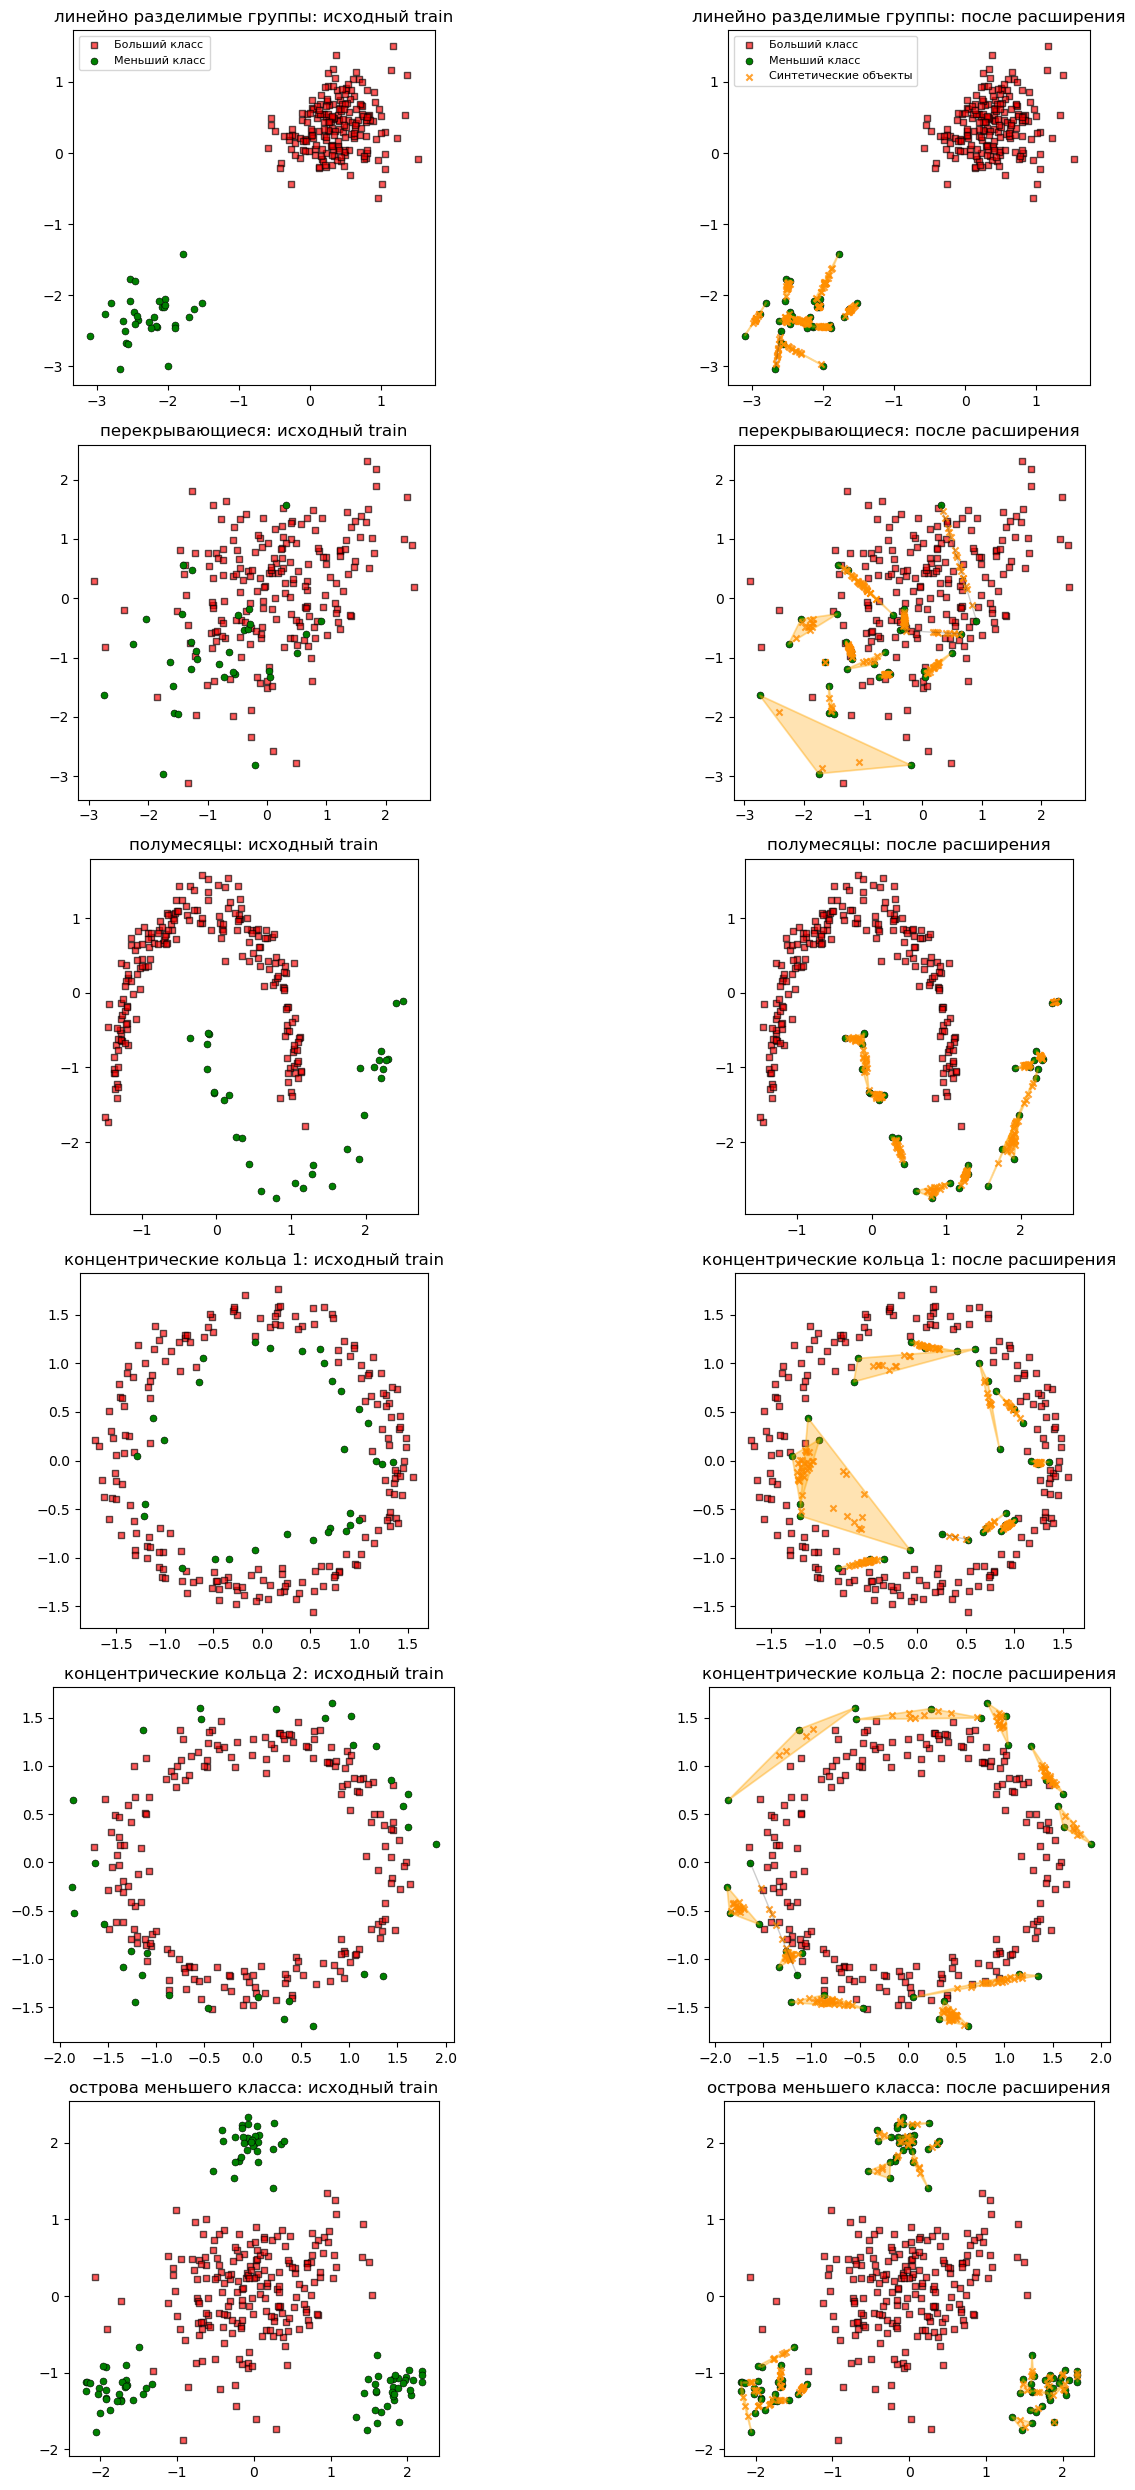

In [12]:
def draw_original(ax, X, y, title):
    ax.scatter(X[y == 0, 0], X[y == 0, 1], s=20, c='red', edgecolor='black',
               marker='s', alpha=.65, label='Больший класс')
    ax.scatter(X[y == 1, 0], X[y == 1, 1], s=25, c='green', edgecolor='black',
               linewidth=.4, label='Меньший класс')
    ax.set_title(title)
    ax.set_aspect('equal', adjustable='box')

def draw_extended(ax, result, title):
    X_train, y_train = result['train']
    info = result['info']
    X_syn = info['X_synthetic']
    X1 = X_train[y_train == 1]

    ax.scatter(X_train[y_train == 0, 0], X_train[y_train == 0, 1],
               s=20, c='red', marker='s', edgecolor='black', alpha=.65, label='Больший класс')
    ax.scatter(X1[:, 0], X1[:, 1], s=25, c='green', edgecolor='black',
               linewidth=.4, label='Меньший класс')

    #оболочки кластеров
    for idx in info['clusters']:
        Q = X1[idx]
        if len(Q) >= 3:
            try:
                hull = ConvexHull(Q)
                polygon = Q[hull.vertices]
                ax.fill(polygon[:, 0], polygon[:, 1], color='orange', alpha=.3)
                ax.plot(np.r_[polygon[:, 0], polygon[0, 0]],
                        np.r_[polygon[:, 1], polygon[0, 1]],
                        color='orange', alpha=.2)
            except Exception:
                pass  # выделять нет смысла
        elif len(Q) == 2:
            ax.plot(Q[:, 0], Q[:, 1], color='black', alpha=.2, lw=1)

    ax.scatter(X_syn[:, 0], X_syn[:, 1], s=20, marker='x', c='darkorange',
               alpha=.8, label='Синтетические объекты')
    ax.set_title(title)
    ax.set_aspect('equal', adjustable='box')

fig, axes = plt.subplots(len(SCENARIOS), 2, figsize=(15, 25))
for row, name in enumerate(SCENARIOS):
    X_train, y_train = results[name]['train']
    draw_original(axes[row, 0], X_train, y_train,
                  f'{TITLES[name]}: исходный train')
    draw_extended(axes[row, 1], results[name],
                  f'{TITLES[name]}: после расширения')
    if row == 0:
        axes[row, 0].legend(loc='best', fontsize=8)
        axes[row, 1].legend(loc='best', fontsize=8)
fig.tight_layout()
plt.show()

кластеры (индексы точек меньшинства): [[2, 0, 1]]
   cluster  size  distance_to_majority  n_synthetic    indices
0        1     3              0.291484            9  (2, 0, 1) 

реально выдано синтетических точек: 9
точек большинства внутри оболочки кластера: 0
внутри кольца большинства (r < 1):        299 из 300
ближе к большинству, чем к меньшинству:   296 из 300
центр масс синтетики: (+0.03, +0.00)  — это центр окружности


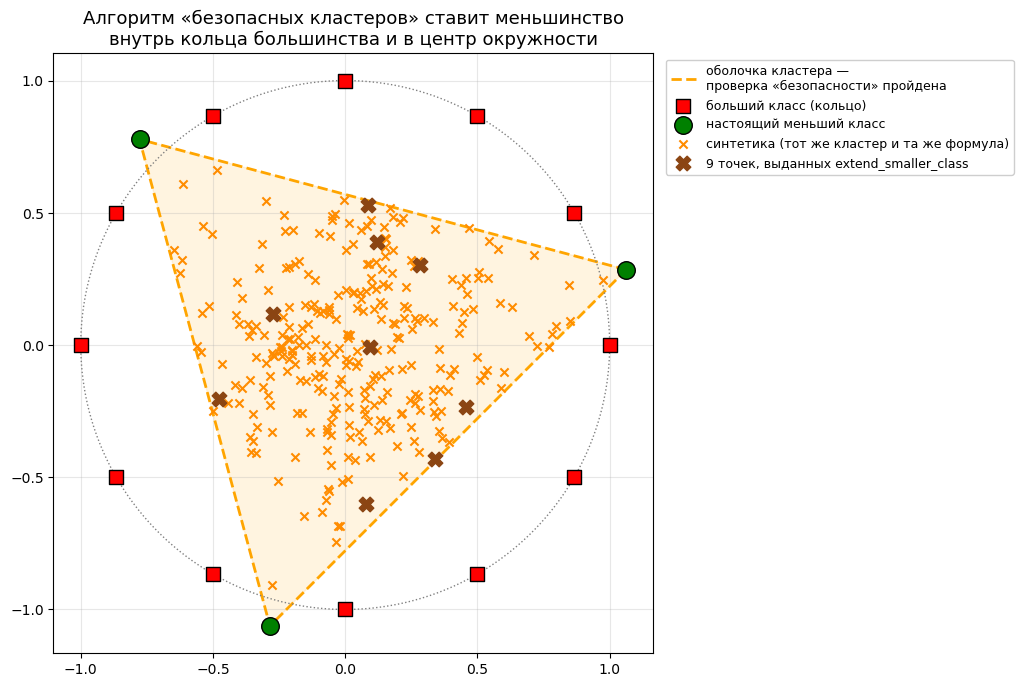

In [13]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial import ConvexHull

# ---------------------------------------------------------------
# 1. Данные: «окружность»
#    Больший класс — 12 точек на окружности r = 1
#    Меньший класс — 3 точки на окружности r = 1.1,
#    сдвинутые на 15°, т.е. ровно между точками большинства
# ---------------------------------------------------------------
R_maj, R_min = 1.0, 1.1
a_maj = np.deg2rad(np.arange(0, 360, 30))     # 0, 30, ..., 330
a_min = np.deg2rad([15, 135, 255])

X_maj = R_maj * np.c_[np.cos(a_maj), np.sin(a_maj)]
X_min = R_min * np.c_[np.cos(a_min), np.sin(a_min)]

X = np.vstack([X_maj, X_min])
y = np.r_[np.zeros(len(X_maj), dtype=int), np.ones(len(X_min), dtype=int)]

# ---------------------------------------------------------------
# 2. Запускаем настоящий алгоритм из ноутбука
#    (stop_rule='paper' в 2D => кластер не больше 3 точек,
#     поэтому все 3 точки меньшинства сливаются в один кластер)
# ---------------------------------------------------------------
X_ext, y_ext, info = extend_smaller_class(X, y, random_state=0)

print("кластеры (индексы точек меньшинства):", info['clusters'])
print(info['table'], "\n")
print("реально выдано синтетических точек:", len(info['X_synthetic']))

# ---------------------------------------------------------------
# 3. Проверка «безопасности» — ровно то, что делает any_majority_inside
# ---------------------------------------------------------------
hull = ConvexHull(X_min)
eq = hull.equations                                # A·x + b <= 0 — внутри
inside = np.all(eq[:, :2] @ X_maj.T + eq[:, 2:3] <= 1e-9, axis=0)
print("точек большинства внутри оболочки кластера:", inside.sum())

# ---------------------------------------------------------------
# 4. Для наглядности — много точек из того же кластера
#    той же формулой, что в ноутбуке (normalized_uniform_weights)
# ---------------------------------------------------------------
rng = np.random.default_rng(0)
idx = info['clusters'][0]
Q = X[y == 1][idx]                                 # 3 вершины кластера
N = 300
W = np.vstack([normalized_uniform_weights(len(Q), rng) for _ in range(N)])
synth = W @ Q

# ---------------------------------------------------------------
# 5. Количественное доказательство провала
# ---------------------------------------------------------------
r_syn  = np.linalg.norm(synth, axis=1)
d_min  = np.linalg.norm(synth[:, None] - X_min[None], axis=2).min(1)
d_maj  = np.linalg.norm(synth[:, None] - X_maj[None], axis=2).min(1)

print(f"внутри кольца большинства (r < 1):        {(r_syn < R_maj).sum():3d} из {N}")
print(f"ближе к большинству, чем к меньшинству:   {(d_maj < d_min).sum():3d} из {N}")
print(f"центр масс синтетики: ({synth[:,0].mean():+.2f}, {synth[:,1].mean():+.2f})"
      "  — это центр окружности")

# ---------------------------------------------------------------
# 6. Картинка
# ---------------------------------------------------------------
fig, ax = plt.subplots(figsize=(10, 8))

poly = X_min[ConvexHull(X_min).vertices]
poly = np.vstack([poly, poly[0]])
ax.fill(poly[:, 0], poly[:, 1], color='orange', alpha=.12, zorder=1)
ax.plot(poly[:, 0], poly[:, 1], '--', color='orange', lw=2, zorder=2,
        label='оболочка кластера —\nпроверка «безопасности» пройдена')

t = np.linspace(0, 2*np.pi, 400)
ax.plot(np.cos(t), np.sin(t), ':', color='gray', lw=1)

ax.scatter(X_maj[:, 0], X_maj[:, 1], s=90, c='red', marker='s',
           edgecolor='black', zorder=3, label='больший класс (кольцо)')
ax.scatter(X_min[:, 0], X_min[:, 1], s=160, c='green', edgecolor='black',
           zorder=4, label='настоящий меньший класс')
ax.scatter(synth[:, 0], synth[:, 1], s=35, marker='x', c='darkorange',
           zorder=5, label='синтетика (тот же кластер и та же формула)')
ax.scatter(info['X_synthetic'][:, 0], info['X_synthetic'][:, 1],
           s=110, marker='X', c='saddlebrown', zorder=6,
           label='9 точек, выданных extend_smaller_class')

ax.set_aspect('equal')
ax.set_title('Алгоритм «безопасных кластеров» ставит меньшинство\n'
             'внутрь кольца большинства и в центр окружности', fontsize=13)
ax.legend(loc='upper left', bbox_to_anchor=(1.01, 1.0), fontsize=9, framealpha=.95)
ax.grid(alpha=.3)
fig.subplots_adjust(left=.08, right=.68, top=.9, bottom=.08)
plt.show()

In [14]:
!pip install ripser

In [15]:
!pip install ripser persim

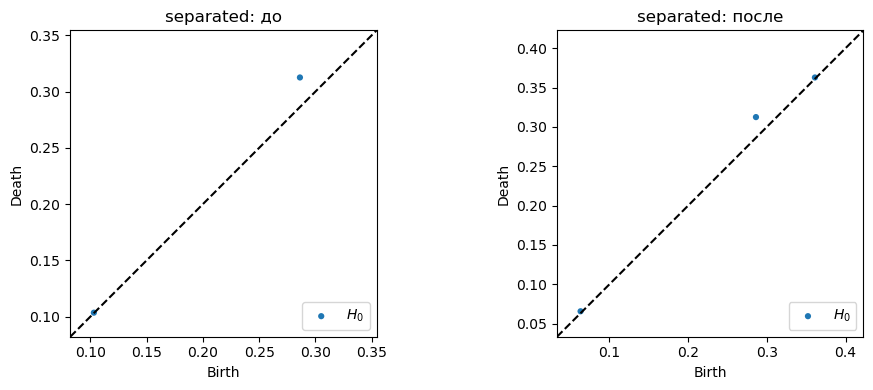

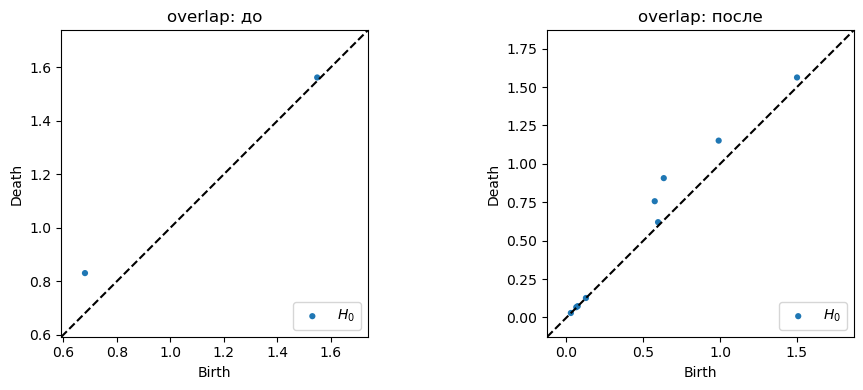

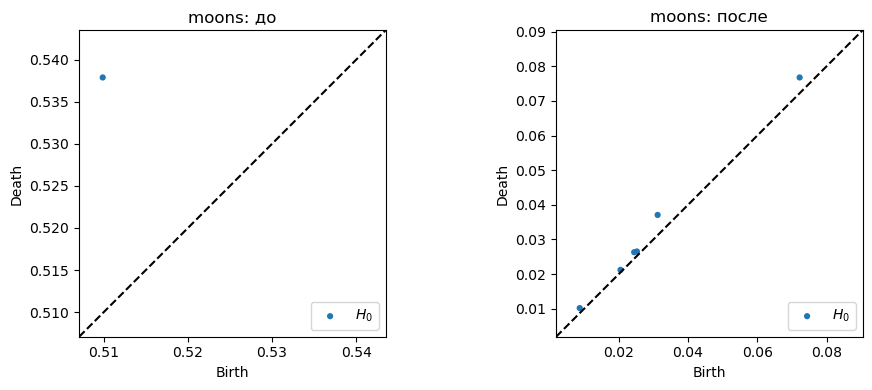

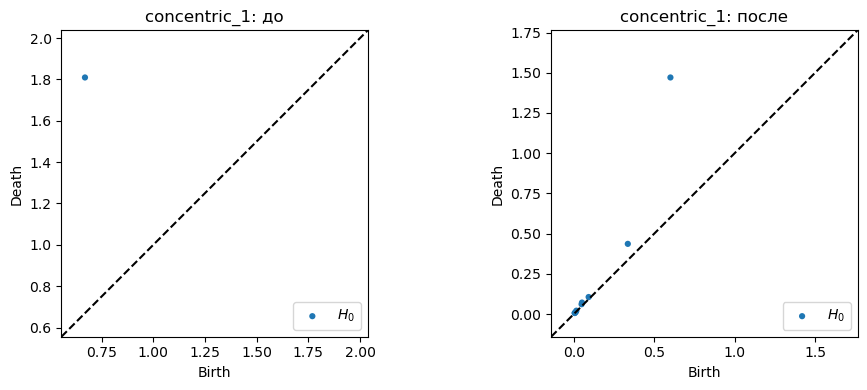

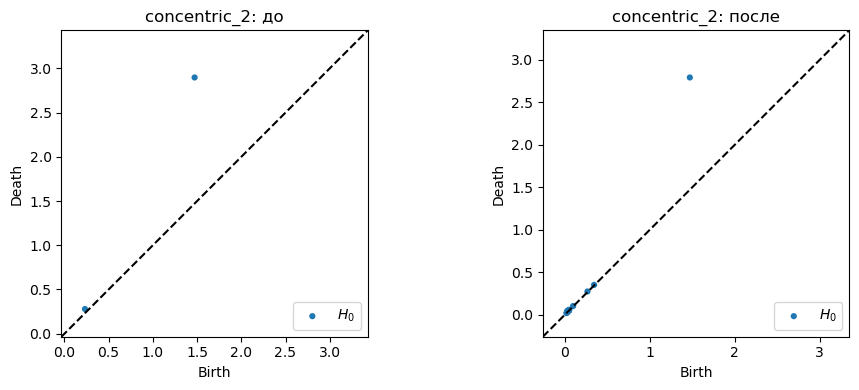

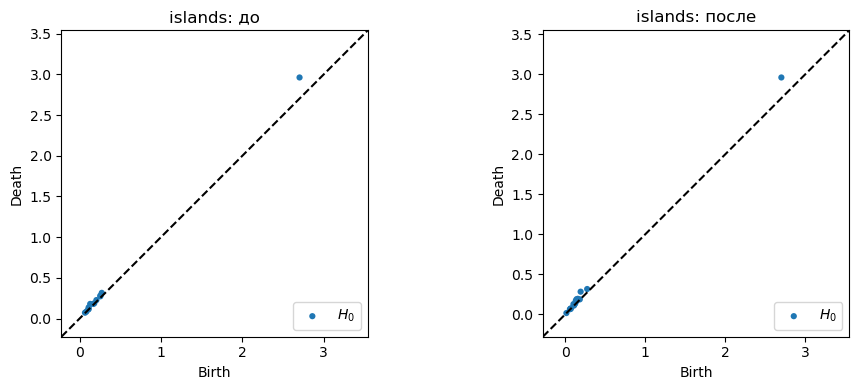

,scenario,H1_before,H1_after,delta_H1
0,separated,0.026,0.026,0.000
1,overlap,0.150,0.274,0.124
2,moons,0.028,0.006,-0.022
3,concentric_1,1.140,0.870,-0.270
4,concentric_2,1.425,1.321,-0.105
5,islands,0.259,0.259,0.000


In [16]:

from ripser import ripser
from persim import plot_diagrams
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def longest_h1(dgm):
    lengths = [
        death - birth
        for birth, death in dgm
        if np.isfinite(death)
    ]
    return max(lengths, default=0.0)

rows = []

for name, result in results.items():
    X_train, y_train = result['train']
    X_ext, y_ext = result['extended']
    minority = result['info']['minority_label']

    X_before = X_train[y_train == minority]
    X_after = X_ext[y_ext == minority]

    dgm_before = ripser(X_before, maxdim=1)['dgms'][1]
    dgm_after = ripser(X_after, maxdim=1)['dgms'][1]

    L_before = longest_h1(dgm_before)
    L_after = longest_h1(dgm_after)

    rows.append({
        'scenario': name,
        'H1_before': L_before,
        'H1_after': L_after,
        'delta_H1': L_after - L_before
    })

    fig, axes = plt.subplots(1, 2, figsize=(10, 4))

    plot_diagrams([dgm_before], ax=axes[0])
    axes[0].set_title(f'{name}: до')

    plot_diagrams([dgm_after], ax=axes[1])
    axes[1].set_title(f'{name}: после')

    plt.tight_layout()
    plt.show()

topology_results = pd.DataFrame(rows)
display(topology_results.round(3))


Исходных точек: 50
Синтетических точек: 250
H1 до: 0.7043
H1 после: 0.7043
Изменение: 0.0
Исходных точек при r < 0.3: 0
Синтетических точек при r < 0.3: 0


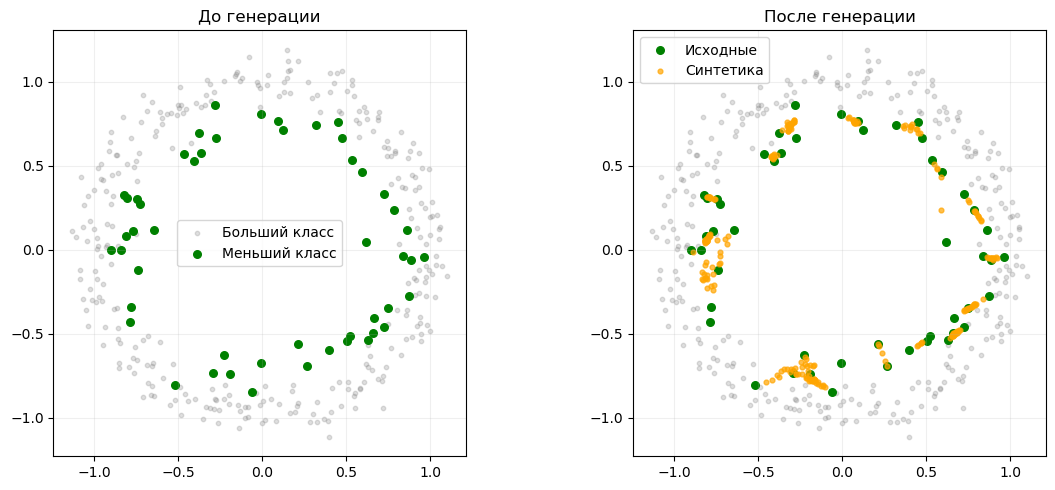

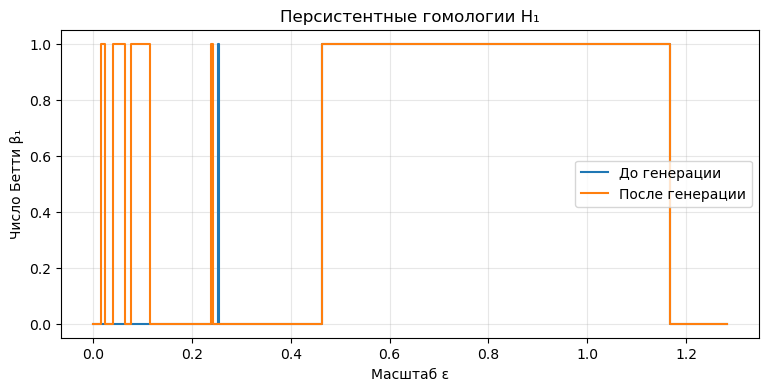

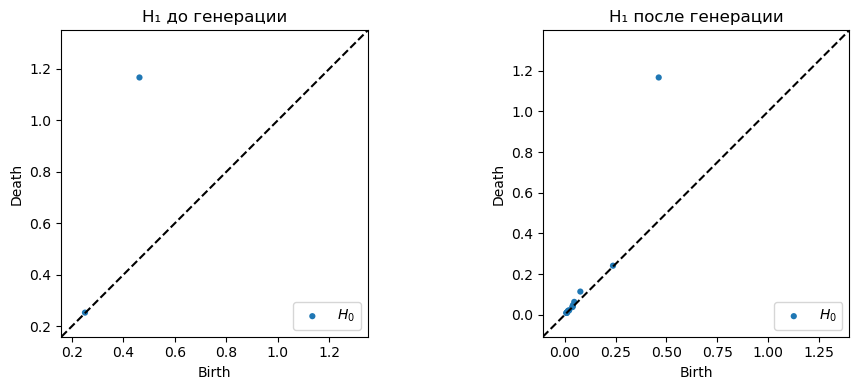

In [17]:

import numpy as np
import matplotlib.pyplot as plt
from ripser import ripser

# 1. Создаём данные: меньший класс — внутреннее кольцо
X, y = scenario_data('concentric_1', seed=42)

minority = X[y == 1]
majority = X[y == 0]

# 2. Запускаем ТВОЙ алгоритм
X_ext, y_ext, info = extend_smaller_class(
    X, y, random_state=42
)

synthetic = info['X_synthetic']
after = np.vstack([minority, synthetic])

# 3. Считаем персистентные гомологии
dgm_before = ripser(minority, maxdim=1)['dgms'][1]
dgm_after = ripser(after, maxdim=1)['dgms'][1]

def longest_bar(dgm):
    finite = dgm[np.isfinite(dgm[:, 1])]
    if len(finite) == 0:
        return 0.0
    return np.max(finite[:, 1] - finite[:, 0])

L_before = longest_bar(dgm_before)
L_after = longest_bar(dgm_after)

print('Исходных точек:', len(minority))
print('Синтетических точек:', len(synthetic))
print('H1 до:', round(L_before, 4))
print('H1 после:', round(L_after, 4))
print('Изменение:', round(L_after - L_before, 4))

# 4. Проверяем попадание синтетики в центральную область
# Для make_circles внутреннее кольцо имеет радиус около 0.5.
# r < 0.3 — условная центральная запрещённая зона.
r_original = np.linalg.norm(minority, axis=1)
r_synthetic = np.linalg.norm(synthetic, axis=1)

print('Исходных точек при r < 0.3:',
      np.sum(r_original < 0.3))
print('Синтетических точек при r < 0.3:',
      np.sum(r_synthetic < 0.3))

# 5. Визуализация облаков
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].scatter(
    majority[:, 0], majority[:, 1],
    s=10, c='gray', alpha=.25, label='Больший класс'
)
axes[0].scatter(
    minority[:, 0], minority[:, 1],
    s=30, c='green', label='Меньший класс'
)
axes[0].set_title('До генерации')

axes[1].scatter(
    majority[:, 0], majority[:, 1],
    s=10, c='gray', alpha=.25
)
axes[1].scatter(
    minority[:, 0], minority[:, 1],
    s=30, c='green', label='Исходные'
)
axes[1].scatter(
    synthetic[:, 0], synthetic[:, 1],
    s=12, c='orange', alpha=.7, label='Синтетика'
)
axes[1].set_title('После генерации')

for ax in axes:
    ax.set_aspect('equal')
    ax.legend()
    ax.grid(alpha=.2)

plt.tight_layout()
plt.show()

# 6. Кривые Бетти
finite_deaths = np.concatenate([
    dgm_before[np.isfinite(dgm_before[:, 1]), 1],
    dgm_after[np.isfinite(dgm_after[:, 1]), 1]
])

eps_max = finite_deaths.max() * 1.1 if len(finite_deaths) else 1
eps_values = np.linspace(0, eps_max, 500)

def betti_curve(dgm, eps_values):
    return np.array([
        np.sum((dgm[:, 0] <= eps) & (eps < dgm[:, 1]))
        for eps in eps_values
    ])

beta_before = betti_curve(dgm_before, eps_values)
beta_after = betti_curve(dgm_after, eps_values)

plt.figure(figsize=(9, 4))
plt.step(eps_values, beta_before, where='post',
         label='До генерации')
plt.step(eps_values, beta_after, where='post',
         label='После генерации')

plt.xlabel('Масштаб ε')
plt.ylabel('Число Бетти β₁')
plt.title('Персистентные гомологии H₁')
plt.legend()
plt.grid(alpha=.3)
plt.show()

# 7. Диаграммы персистентности
from persim import plot_diagrams

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

plot_diagrams([dgm_before], ax=axes[0])
axes[0].set_title('H₁ до генерации')

plot_diagrams([dgm_after], ax=axes[1])
axes[1].set_title('H₁ после генерации')

plt.tight_layout()
plt.show()


Кластеры: [[0, 1, 2], [3]]
Создано синтетических: 36
Точек в запрещённом круге: 14
Доля: 0.389

Персистентные гомологии:
Max H1 до: 0.5858
Max H1 после: 0.0601
Bottleneck: 0.2929
β1 до при ε=1.5: 1
β1 после при ε=1.5: 0


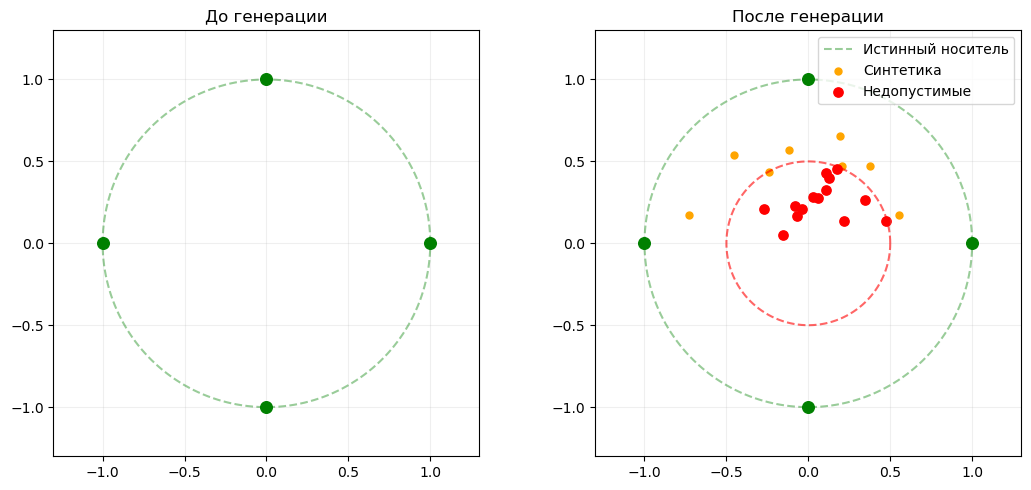

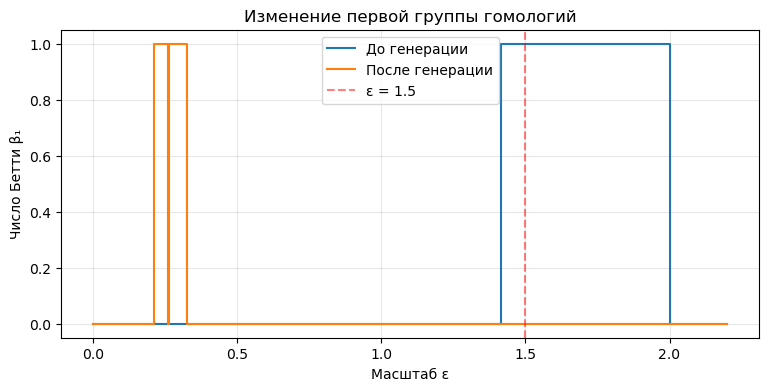

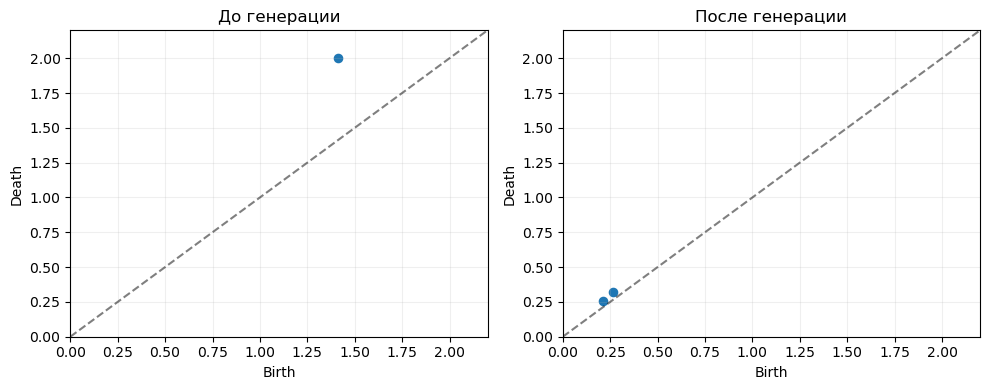


КОНТРПРИМЕР ПОДТВЕРЖДЁН


In [18]:

import numpy as np
import matplotlib.pyplot as plt
from ripser import ripser
from persim import bottleneck

# 1. Четыре точки на единичной окружности
X1 = np.array([
    [1., 0.],
    [0., 1.],
    [-1., 0.],
    [0., -1.]
])

# 2. Больший класс далеко справа
rng = np.random.default_rng(0)
X2 = np.array([3., 0.]) + rng.normal(0, 0.025, (40, 2))

X = np.vstack([X2, X1])
y = np.r_[np.zeros(len(X2), dtype=int),
          np.ones(len(X1), dtype=int)]

# 3. Запускаем исходный алгоритм без изменений
X_ext, y_ext, info = extend_smaller_class(
    X, y, random_state=42
)

S = info['X_synthetic']
Y = np.vstack([X1, S])

print("Кластеры:", info['clusters'])
print("Создано синтетических:", len(S))

# Проверяем, что проверка безопасности пройдена
for cluster in info['clusters']:
    assert not any_majority_inside(X1[cluster], X2)

# 4. Проверяем нарушение истинного носителя
r = np.linalg.norm(S, axis=1)
invalid = r < 0.5

print("Точек в запрещённом круге:", invalid.sum())
print("Доля:", round(invalid.mean(), 3))

# 5. Персистентные гомологии
d_before = ripser(X1, maxdim=1)['dgms'][1]
d_after = ripser(Y, maxdim=1)['dgms'][1]

def longest_bar(d):
    finite = d[np.isfinite(d[:, 1])]
    return max((b - a for a, b in finite), default=0.)

def beta1(d, eps):
    return np.sum((d[:, 0] <= eps) & (eps < d[:, 1]))

eps = 1.5

print("\nПерсистентные гомологии:")
print("Max H1 до:", round(longest_bar(d_before), 4))
print("Max H1 после:", round(longest_bar(d_after), 4))
print("Bottleneck:", round(bottleneck(d_before, d_after), 4))
print("β1 до при ε=1.5:", beta1(d_before, eps))
print("β1 после при ε=1.5:", beta1(d_after, eps))

# 6. Визуализация расположения точек
theta = np.linspace(0, 2 * np.pi, 400)

fig, axes = plt.subplots(1, 2, figsize=(11, 5))

for ax in axes:
    ax.plot(np.cos(theta), np.sin(theta),
            '--', c='green', alpha=.4, label='Истинный носитель')
    ax.scatter(X1[:, 0], X1[:, 1],
               s=70, c='green', zorder=4)
    ax.set_aspect('equal')
    ax.set_xlim(-1.3, 1.3)
    ax.set_ylim(-1.3, 1.3)
    ax.grid(alpha=.2)

axes[0].set_title('До генерации')

axes[1].scatter(S[:, 0], S[:, 1],
                s=25, c='orange', label='Синтетика')
axes[1].scatter(S[invalid, 0], S[invalid, 1],
                s=45, c='red', label='Недопустимые')
axes[1].plot(0.5 * np.cos(theta),
             0.5 * np.sin(theta),
             '--', c='red', alpha=.6)
axes[1].set_title('После генерации')
axes[1].legend()

plt.tight_layout()
plt.show()

# 7. Кривые Бетти
eps_values = np.linspace(0, 2.2, 500)

b_before = [beta1(d_before, e) for e in eps_values]
b_after = [beta1(d_after, e) for e in eps_values]

plt.figure(figsize=(9, 4))
plt.step(eps_values, b_before, where='post',
         label='До генерации')
plt.step(eps_values, b_after, where='post',
         label='После генерации')
plt.axvline(1.5, c='red', ls='--', alpha=.5,
            label='ε = 1.5')
plt.xlabel('Масштаб ε')
plt.ylabel('Число Бетти β₁')
plt.title('Изменение первой группы гомологий')
plt.legend()
plt.grid(alpha=.3)
plt.show()

# 8. Диаграммы персистентности
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, d, title in zip(
    axes,
    [d_before, d_after],
    ['До генерации', 'После генерации']
):
    ax.plot([0, 2.2], [0, 2.2], 'k--', alpha=.5)
    if len(d):
        ax.scatter(d[:, 0], d[:, 1], s=35)
    ax.set_xlim(0, 2.2)
    ax.set_ylim(0, 2.2)
    ax.set_xlabel('Birth')
    ax.set_ylabel('Death')
    ax.set_title(title)
    ax.grid(alpha=.2)

plt.tight_layout()
plt.show()

# 9. Проверка контрпримера
assert invalid.sum() > 0, "Нет точек в запрещённой области"
assert beta1(d_before, 1.5) == 1
assert beta1(d_after, 1.5) == 0

print("\nКОНТРПРИМЕР ПОДТВЕРЖДЁН")


In [19]:
!pip install gudhi

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.6/8.6 MB 1.3 MB/s  0:00:06m 1.3 MB/s eta 0:00:010m


In [20]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.spatial import cKDTree
from gudhi import AlphaComplex

def sample_manifold(name, n, rng):
    u = rng.uniform(0, 2*np.pi, n)
    v = rng.uniform(0, 2*np.pi, n)

    if name in ['torus', 'warped_torus']:
        R, r = 2.0, 0.8
        x = (R + r*np.cos(v)) * np.cos(u)
        y = (R + r*np.cos(v)) * np.sin(u)
        z = r*np.sin(v)

        if name == 'warped_torus':
            z = z + 0.7*np.sin(3*u)
            x = x + 0.3*np.sin(2*u)*np.sin(v)

    elif name == 'sphere':
        z = rng.uniform(-1, 1, n)
        phi = rng.uniform(0, 2*np.pi, n)
        radius = np.sqrt(1-z**2)
        x = radius*np.cos(phi)
        y = radius*np.sin(phi)

    elif name == 'cylinder':
        z = rng.uniform(-1.5, 1.5, n)
        x = np.cos(u)
        y = np.sin(u)

    elif name == 'two_tori':
        R, r = 1.2, 0.45
        x = (R + r*np.cos(v))*np.cos(u)
        y = (R + r*np.cos(v))*np.sin(u)
        z = r*np.sin(v)

        # Две непересекающиеся компоненты
        shift = rng.choice([-2.0, 2.0], size=n)
        x = x + shift

    else:
        raise ValueError(name)

    return np.column_stack([x, y, z])


SCENARIOS = [
    'torus',
    'warped_torus',
    'sphere',
    'cylinder',
    'two_tori'
]

BETTI_THEORY = {
    'torus': (1, 2, 1),
    'warped_torus': (1, 2, 1),
    'sphere': (1, 0, 1),
    'cylinder': (1, 1, 0),
    'two_tori': (2, 4, 2)
}


In [21]:

def run_manifold_experiment(name, seed=42, n_minority=60,
                            n_majority=180):
    rng = np.random.default_rng(seed)

    # Меньший класс на многообразии
    X_min = sample_manifold(name, n_minority, rng)

    # Больший класс далеко от многообразия
    X_maj = rng.normal(
        loc=[12, 12, 12],
        scale=0.3,
        size=(n_majority, 3)
    )

    X = np.vstack([X_maj, X_min])
    y = np.r_[
        np.zeros(n_majority, dtype=int),
        np.ones(n_minority, dtype=int)
    ]

    # Исходный алгоритм из твоего ноутбука
    X_ext, y_ext, info = extend_smaller_class(
        X, y, random_state=seed
    )

    S = np.asarray(info['X_synthetic']).reshape(-1, 3)
    X_after = np.vstack([X_min, S])

    # Контроль: столько же новых точек на многообразии
    X_control = np.vstack([
        X_min,
        sample_manifold(name, len(S), rng)
    ])

    return {
        'before': X_min,
        'after': X_after,
        'control': X_control,
        'synthetic': S,
        'info': info
    }


experiments = {
    name: run_manifold_experiment(name)
    for name in SCENARIOS
}

for name, result in experiments.items():
    print(
        name,
        '| исходных:', len(result['before']),
        '| синтетических:', len(result['synthetic'])
    )


torus | исходных: 60 | синтетических: 120
warped_torus | исходных: 60 | синтетических: 120
sphere | исходных: 60 | синтетических: 120
cylinder | исходных: 60 | синтетических: 120
two_tori | исходных: 60 | синтетических: 120


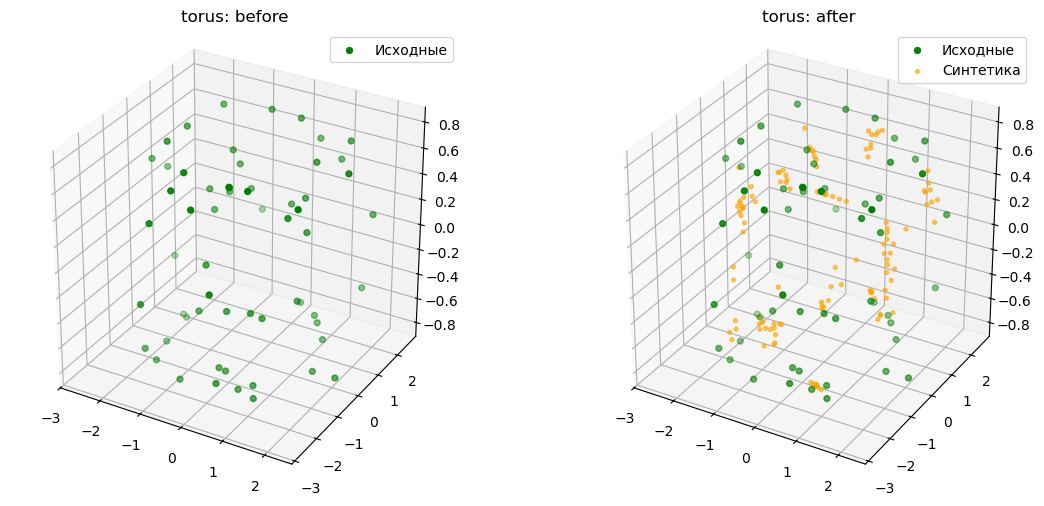

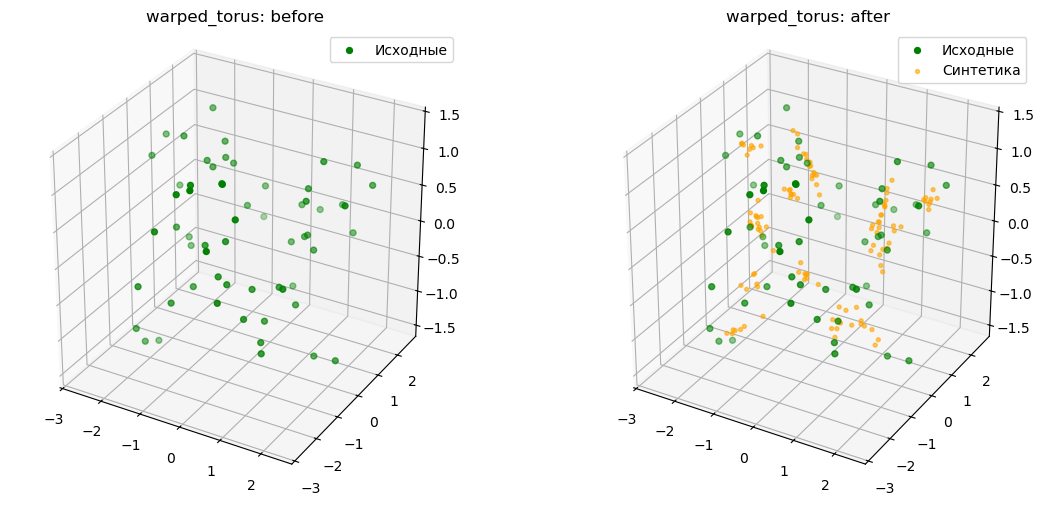

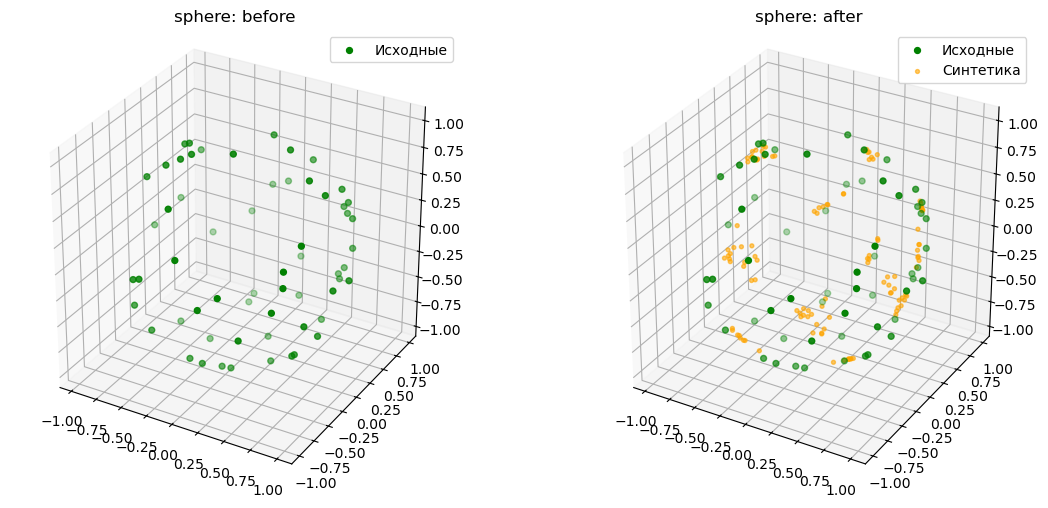

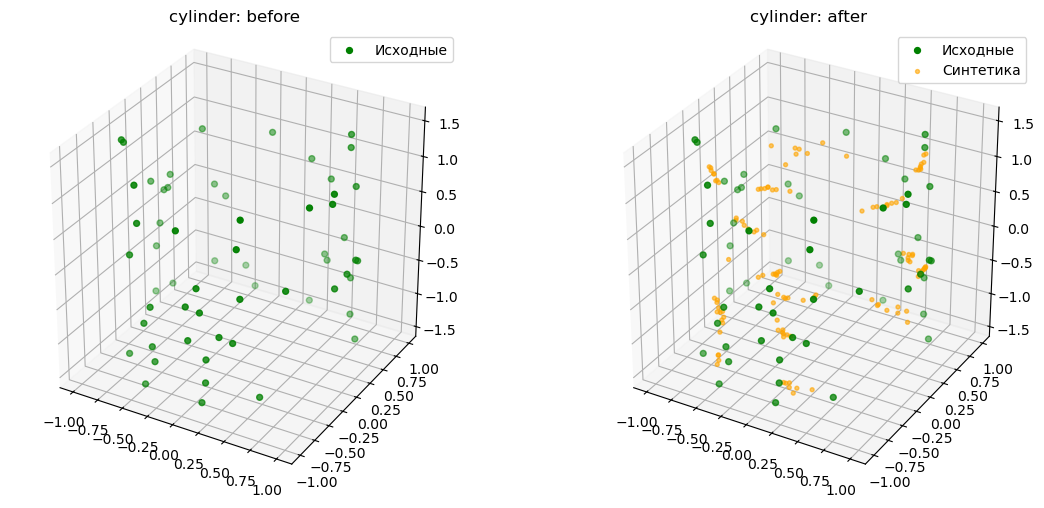

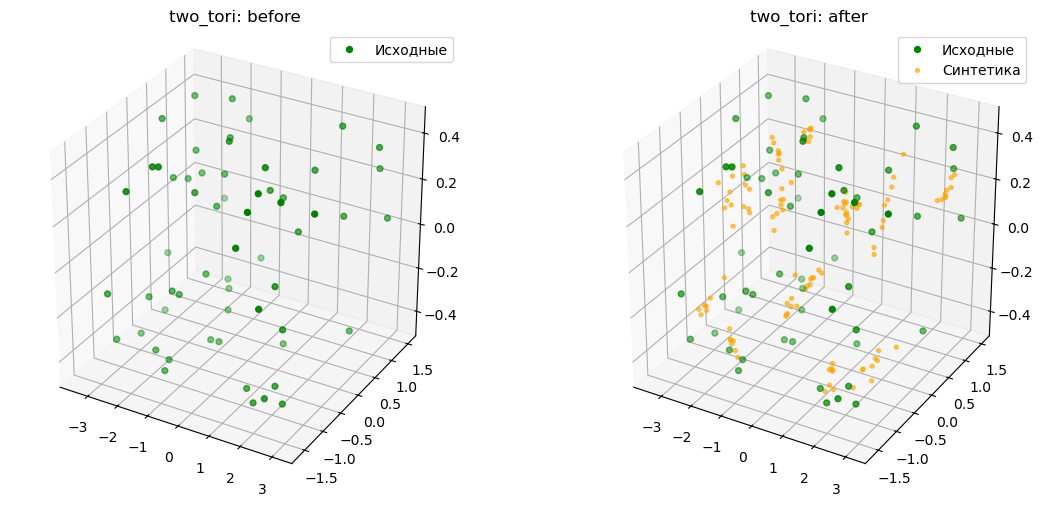

In [22]:

for name, result in experiments.items():
    fig = plt.figure(figsize=(12, 5))

    for i, key in enumerate(['before', 'after']):
        ax = fig.add_subplot(1, 2, i+1, projection='3d')

        X = result['before']
        ax.scatter(
            X[:, 0], X[:, 1], X[:, 2],
            s=18, c='green', label='Исходные'
        )

        if key == 'after':
            S = result['synthetic']
            ax.scatter(
                S[:, 0], S[:, 1], S[:, 2],
                s=8, c='orange', alpha=0.6,
                label='Синтетика'
            )

        ax.set_title(f'{name}: {key}')
        ax.set_box_aspect([1, 1, 1])
        ax.legend()

    plt.tight_layout()
    plt.show()


In [23]:

def compute_persistence(X):
    alpha = AlphaComplex(points=X)
    st = alpha.create_simplex_tree()
    st.compute_persistence()

    diagrams = {}

    for dim in range(3):
        dgm = st.persistence_intervals_in_dimension(dim)
        dgm = np.asarray(dgm).reshape(-1, 2)

        # Alpha filtration: squared radius -> radius
        diagrams[dim] = np.sqrt(np.maximum(dgm, 0))

    return diagrams


def betti_at(dgm, eps):
    return int(np.sum(
        (dgm[:, 0] <= eps) &
        (eps < dgm[:, 1])
    ))


def max_persistence(dgm):
    finite = dgm[np.isfinite(dgm[:, 1])]

    if len(finite) == 0:
        return 0.0

    return float(np.max(finite[:, 1] - finite[:, 0]))


for name, result in experiments.items():
    print('Вычисляем:', name)

    result['diagrams'] = {
        key: compute_persistence(result[key])
        for key in ['before', 'after', 'control']
    }

print('Готово')


Вычисляем: torus
Вычисляем: warped_torus
Вычисляем: sphere
Вычисляем: cylinder
Вычисляем: two_tori
Готово


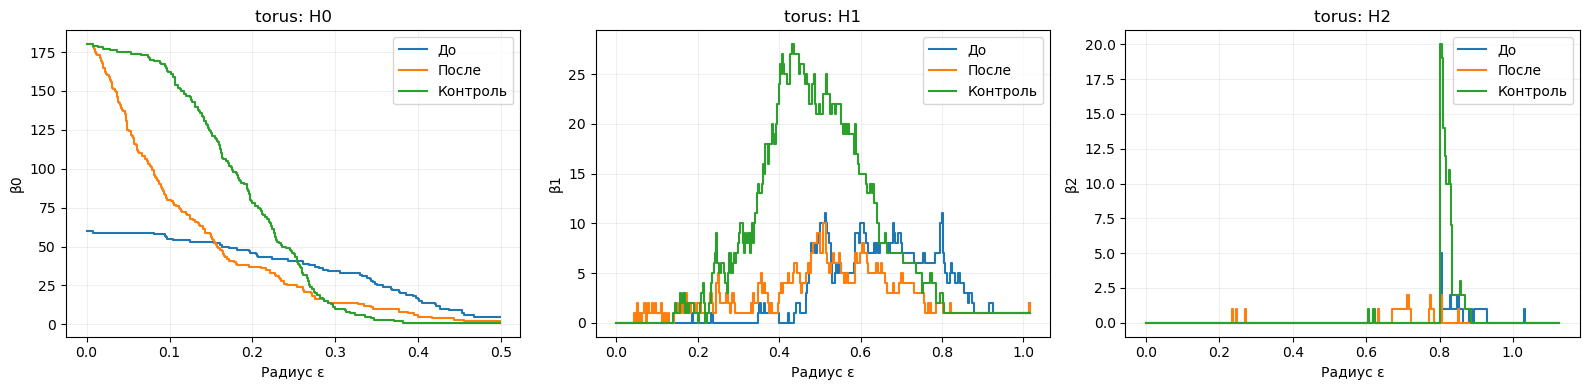

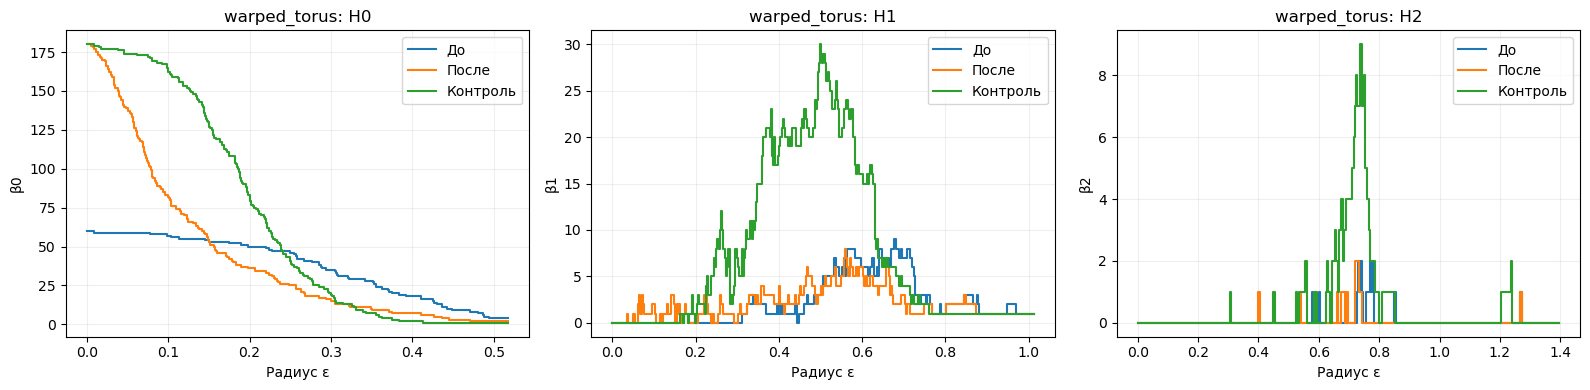

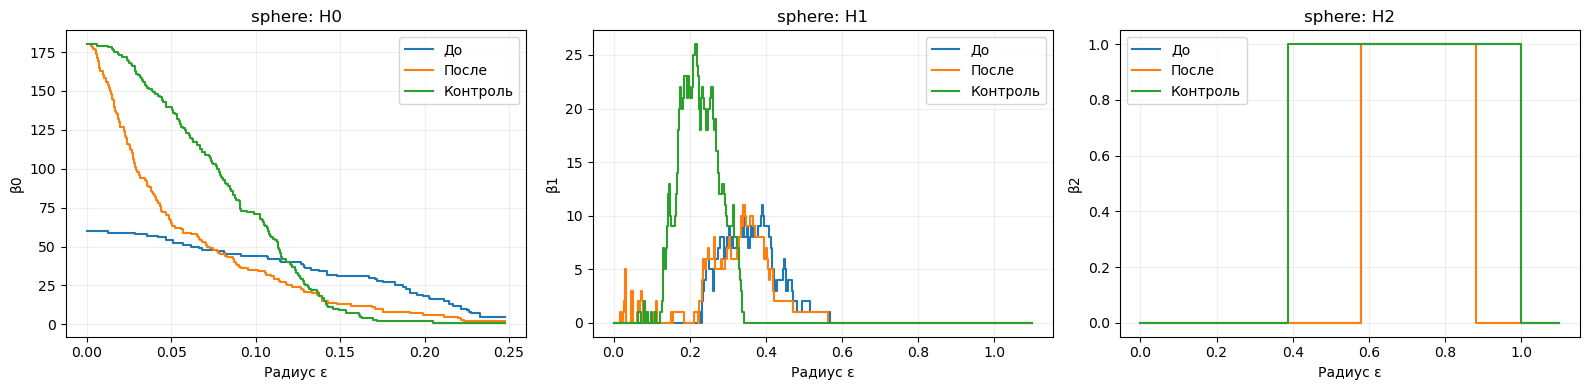

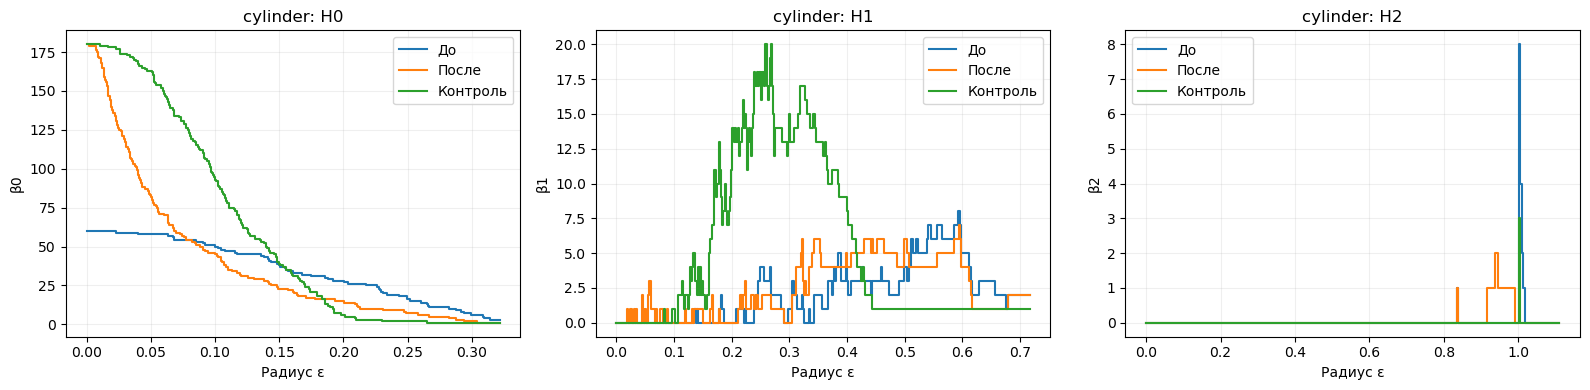

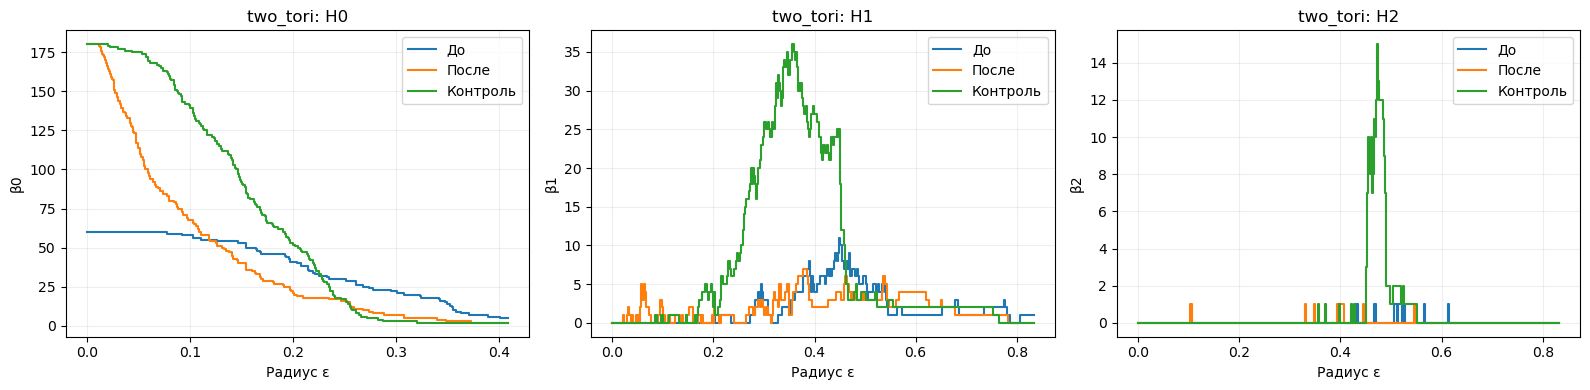

In [24]:

for name, result in experiments.items():
    dgms = result['diagrams']

    fig, axes = plt.subplots(1, 3, figsize=(16, 4))

    for dim, ax in enumerate(axes):
        finite_deaths = np.concatenate([
            dgms[key][dim][
                np.isfinite(dgms[key][dim][:, 1]), 1
            ]
            for key in ['before', 'after', 'control']
        ])

        eps_max = (
            np.quantile(finite_deaths, 0.98) * 1.1
            if len(finite_deaths) else 1.0
        )
        eps = np.linspace(0, eps_max, 400)

        for key, label in [
            ('before', 'До'),
            ('after', 'После'),
            ('control', 'Контроль')
        ]:
            dgm = dgms[key][dim]
            beta = [betti_at(dgm, e) for e in eps]

            ax.step(eps, beta, where='post', label=label)

        ax.set_title(f'{name}: H{dim}')
        ax.set_xlabel('Радиус ε')
        ax.set_ylabel(f'β{dim}')
        ax.grid(alpha=0.2)
        ax.legend()

    plt.tight_layout()
    plt.show()
